In [84]:
# Dependencies

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

In [85]:
# Data

df = pd.read_csv('l-38_train.csv',usecols=['Age','Fare','Survived'])


In [86]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


now lets beging with overview and analysis


In [87]:
df.isnull().mean() * 100


Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [88]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [89]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)


In [90]:
X_train.head()

,Age,Fare
30,40.0,27.7208
10,4.0,16.7000
873,47.0,9.0000
182,9.0,31.3875
876,20.0,9.8458


In [91]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [92]:
X_test.sample()


,Age,Fare,Age_imputed
614,35.0,8.05,35.0


In [93]:
X_train.sample()


,Age,Fare,Age_imputed
124,54.0,77.2875,54.0


In [94]:
X_train['Age_imputed']

30     40.0
10      4.0
873    47.0
182     9.0
876    20.0
       ... 
534    30.0
584     NaN
493    71.0
527     NaN
168     NaN
Name: Age_imputed, Length: 712, dtype: float64

In [95]:
X_train['Age_imputed'].isnull()

30     False
10     False
873    False
182    False
876    False
       ...  
534    False
584     True
493    False
527     True
168     True
Name: Age_imputed, Length: 712, dtype: bool

In [96]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()]

77    NaN
868   NaN
334   NaN
295   NaN
792   NaN
       ..
674   NaN
466   NaN
584   NaN
527   NaN
168   NaN
Name: Age_imputed, Length: 148, dtype: float64

In [97]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

array([27.  , 33.  , 44.  , 34.  , 30.  , 52.  , 39.  , 24.  , 24.  ,
       44.  , 58.  , 60.  ,  0.83, 21.  , 47.  ,  9.  , 47.  , 52.  ,
       18.  , 32.  , 32.  , 19.  , 16.  , 32.  , 34.  , 29.  , 16.  ,
       40.  , 24.  , 21.  , 21.  , 35.  , 16.  ,  8.  , 34.  ,  0.67,
       31.  , 29.  ,  2.  , 47.  , 19.  , 22.  , 61.  , 18.  ,  3.  ,
       21.  , 34.  , 32.  , 51.  , 49.  , 35.  ,  5.  , 25.  , 58.  ,
       22.  , 21.  , 43.  ,  8.  , 25.  , 17.  , 30.  ,  0.75, 41.  ,
       36.  , 53.  , 26.  , 30.  , 48.  , 62.  , 24.  , 42.  , 31.  ,
       45.  , 35.  , 43.  , 12.  , 36.  , 70.5 , 14.5 , 25.  , 40.  ,
       19.  , 54.  ,  0.83, 31.  , 17.  , 29.  , 17.  , 48.  , 42.  ,
       28.  , 45.  , 19.  , 16.  , 45.  , 21.  , 34.  ,  4.  , 26.  ,
       31.  , 24.  , 14.  , 28.  , 34.  , 17.  , 26.  , 36.  , 30.  ,
       35.  , 18.  , 56.  , 28.  , 21.  , 49.  , 62.  , 40.  , 28.5 ,
       16.  , 48.  , 25.  , 18.  , 24.  , 33.  , 32.  , 18.  , 50.  ,
        2.  ,  8.  ,

In [98]:
X_train['Age'].isnull().sum()

148

In [99]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
X_test['Age_imputed'][X_test['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values

/var/folders/jd/5681g6rx58xgpr8txbqb17p80000gn/T/ipykernel_39193/3090101260.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_test['Age_imputed'][X_test['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum

In [100]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,24.0
493,71.0,49.5042,71.0
527,NaN,221.7792,39.0


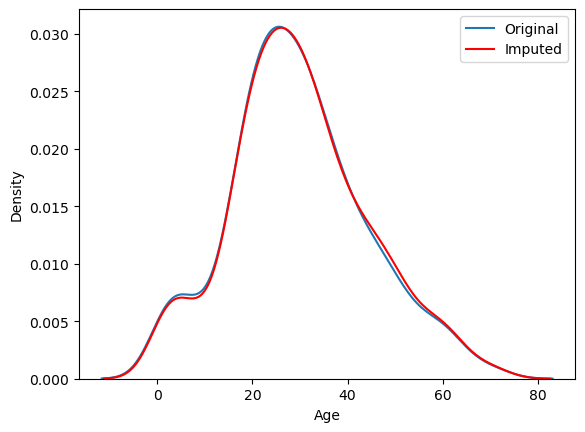

In [101]:
sns.kdeplot(X_train['Age'], label = 'Original')

sns.kdeplot(X_train['Age_imputed'],label ='Imputed',color='red')

plt.legend()
plt.show()

In [102]:
print('Original variable variance: ', X_train['Age'].var())
print('Variance after random imputation: ', X_train['Age_imputed'].var())

Original variable variance:  204.3495133904614
Variance after random imputation:  206.6183277643451


In [103]:
X_train[['Fare', 'Age', 'Age_imputed']].cov()


,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,50.355759
Age,71.512440,204.349513,204.349513
Age_imputed,50.355759,204.349513,206.618328


now we can see that co-variance have changed significantly

## one key point to keep in mind that --> when this technique is in production then everytime the user will fill data our model will use new random values this is cause inconsistency for that same user as he will get diffrent output even for same input__________to fix this is can do this :

In [104]:
# here in this variable the users input will be stored 
input_fare = 2.44

# then we will use this user input as a seed

sampled_value = X_train['Age'].dropna().sample(1, random_state=int(input_fare))

# now lets work on categorical data

In [105]:
data = pd.read_csv('l-38_house-train.csv',usecols=['GarageQual','FireplaceQu', 'SalePrice'])

In [106]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [107]:
data.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [108]:
X = data
y = data['SalePrice']

In [109]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [110]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [111]:
X_train.sample(5)


,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
225,NaN,TA,112000,TA,NaN
152,Gd,TA,190000,TA,Gd
169,TA,TA,228000,TA,TA
837,NaN,TA,100000,TA,NaN
249,TA,TA,277000,TA,TA


In [112]:
X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values

X_train['FireplaceQu_imputed'][X_train['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isnull().sum()).values
X_test['FireplaceQu_imputed'][X_test['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isnull().sum()).values

/var/folders/jd/5681g6rx58xgpr8txbqb17p80000gn/T/ipykernel_39193/856878696.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_tr

In [113]:
temp = pd.concat(
        [
            X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),
            X_train['GarageQual_imputed'].value_counts() / len(X_train)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

In [114]:
temp

,original,imputed
TA,0.951043,0.951199
Fa,0.037171,0.036815
Gd,0.009973,0.010274
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [115]:
temp = pd.concat(
        [
            X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
            X_train['FireplaceQu_imputed'].value_counts() / len(df)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

temp

,original,imputed
Gd,0.494272,0.640853
TA,0.412439,0.547699
Fa,0.040917,0.056117
Po,0.027823,0.033670
Ex,0.024550,0.032548


In [116]:
# now this is a red-flag --> as we can see lot of chnages has occured

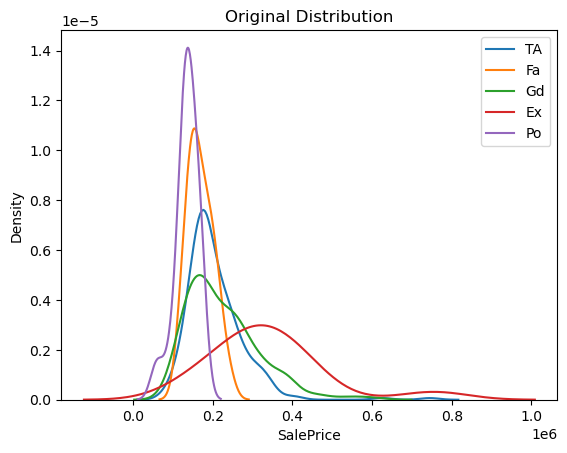

In [117]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'],label=category)
    plt.legend()
    plt.title('Original Distribution')
plt.show()

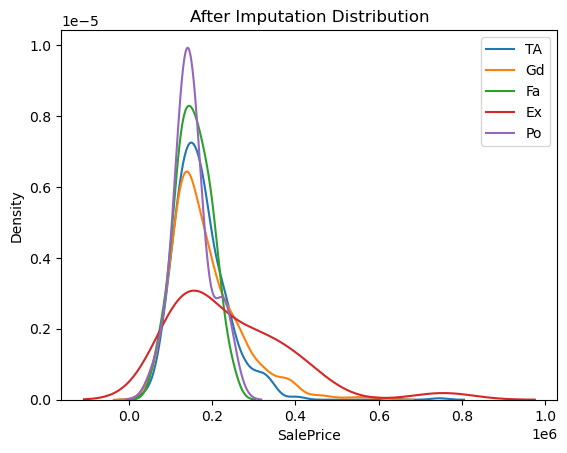

In [118]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'],label=category)
    plt.legend()
    plt.title('After Imputation Distribution')
plt.show()

as we can see entire distribution has changes -- this will cause a lot of issues in linear models